# Compara cinética clásica de flotación con la misma evidencia

Nivel: 3. Requisitos previos: Niveles 1 y 2 de este tema. Tiempo de lectura: 24 minutos.

## Objetivos

Compara cinco formas cinéticas citadas sobre la misma evidencia batch y evalúa por separado la proyección de banco frente a la referencia exacta con tasas distribuidas del motor.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Configura las importaciones y registra versiones. Este paso hace reproducible la ejecución del método.

In [1]:
# Importa herramientas de análisis y registra sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resuelve el pipeline local desde la estructura relativa del repositorio.
repo = Path('../../../').resolve()
sys.path.insert(0, str(repo / 'data-pipeline'))
for package in ('numpy', 'scipy', 'pandas', 'matplotlib', 'nbclient', 'nbformat', 'ipykernel'):
    print(package, importlib.metadata.version(package))

numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores de OreFlow; `data/derived/cases/copper_molybdenum.json`, escenario de autoría propia bajo licencia MIT del proyecto. Observaciones y referencia exacta las genera el modelo, no son datos de planta medidos. Repositorio: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

Las formas candidatas son primer orden, Kelsall rápida/lenta, Klimpel de tasas uniformes, gamma y exponencial estirada. Cada una resume de modo distinto tasas heterogéneas. OreFlow evalúa la misma curva batch virtual y compara proyecciones de banco; una curva ajustada no identifica un mecanismo único.

## Métodos actuales y evidencia

La cinética de primer orden (Kelsall (1961) es una referencia clásica de fracción rápida/lenta. Kelsall y las formas de tasas distribuidas representan mejor la heterogeneidad con más parámetros. OreFlow implementa cinco formas en `pipeline/engine/kinetics.py` y mide tanto error batch como error de proyección frente a su distribución exacta de tasas. Es una comparación controlada, no superioridad demostrada con datos de planta ni un algoritmo nuevo.

Carga un registro cinético comprometido para que todos los modelos usen las mismas observaciones y predicciones.

In [2]:
# Carga un registro cinético comprometido para que todos los modelos usen las mismas observaciones y predicciones.
case_record = json.loads((repo / 'data/derived/cases/copper_molybdenum.json').read_text(encoding='utf-8'))
kinetics = case_record['variants'][0]['trace']['methods']['kinetics']
models = kinetics['models']
print('status:', kinetics['status'], '| payable:', kinetics['species'])
print('bank residence (min):', kinetics['bank']['residence_min'])
print('exact bank recovery (%):', kinetics['bank']['exact_true_flotation_pct'])

status: computed | payable: Cu
bank residence (min): 29.161577021309544
exact bank recovery (%): 93.9822410776771


Compara en paralelo el ajuste batch y error de banco; sus ordenamientos pueden diferir.

In [3]:
# Compara en paralelo el ajuste batch y error de banco; sus ordenamientos pueden diferir.
scores = pd.DataFrame([{'model': m['id'], 'batch RMSE (puntos)': m['rmse_pct'],
                         'Predicción del banco (%)': m['bank_projection_pct'],
                         'Error de banco (puntos)': m['lumping_error_pct'],
                         'Brecha de extrapolación (puntos)': m['ultimate_gap_pct']} for m in models])
display(scores.set_index('model').round(3).sort_values('batch RMSE (puntos)'))

,batch RMSE (puntos),Predicción del banco (%),Error de banco (puntos),Brecha de extrapolación (puntos)
model,,,,
kelsall,0.028,92.662,-1.320,4.540
gamma,0.146,92.951,-1.032,7.034
klimpel,0.398,92.665,-1.318,9.604
stretched_exponential,0.667,90.005,-3.977,1.724
first_order,1.640,87.393,-6.590,0.471


Grafica todos los ajustes en las mismas observaciones batch y luego compara la proyección de banco independiente.

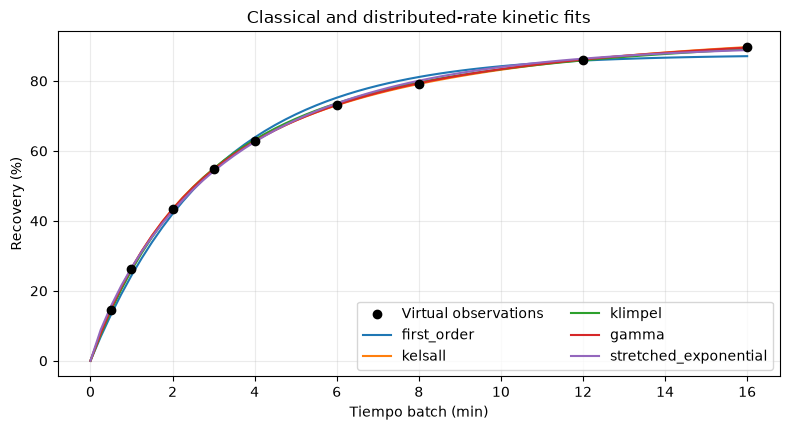

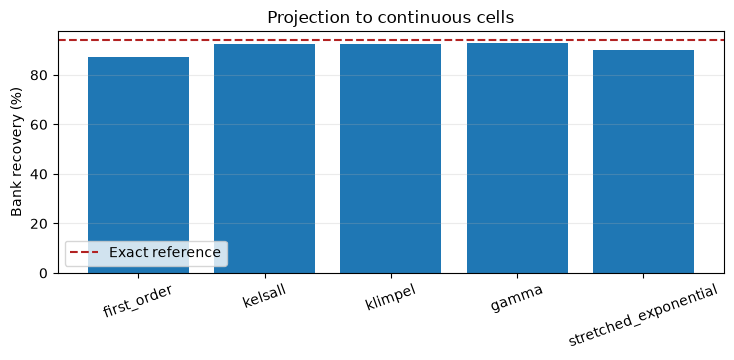

In [4]:
# Grafica todos los ajustes en las mismas observaciones batch y luego compara la proyección de banco independiente.
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.scatter(kinetics['times_min'], kinetics['batch_recovery_pct'], color='black', zorder=4, label='Virtual observations')
for m in models: ax.plot(kinetics['dense_times_min'], m['dense_pct'], label=m['id'])
ax.set(xlabel='Tiempo batch (min)', ylabel='Recovery (%)', title='Classical and distributed-rate kinetic fits')
ax.grid(True, alpha=.25); ax.legend(ncol=2); fig.tight_layout()
fig, ax = plt.subplots(figsize=(7.5, 3.7))
ax.bar([m['id'] for m in models], [m['bank_projection_pct'] for m in models])
ax.axhline(kinetics['bank']['exact_true_flotation_pct'], color='firebrick', linestyle='--', label='Exact reference')
ax.set(ylabel='Bank recovery (%)', title='Projection to continuous cells'); ax.tick_params(axis='x', rotation=20)
ax.legend(); ax.grid(axis='y', alpha=.25); fig.tight_layout()

## Resultados

La primera figura compara ajustes sobre los mismos datos virtuales; la segunda compara proyecciones con el modelo exacto de tasas distribuidas. Miden error de aproximación dentro del motor OreFlow, no precisión en el mundo real. Ajuste batch y proyección de banco responden preguntas diferentes.

## Resumen

La comparación bibliográfica muestra tanto la capacidad como el límite: varias formas clásicas ajustan una curva sintética, pero sus predicciones de banco divergen. OreFlow informa la diferencia en vez de presentar la animación como dinámica de planta.

## Referencias

- https://doi.org/10.1016/S0301-7516(99)00069-1
- https://doi.org/10.5277/ppmp170128
- https://doi.org/10.1016/j.mineng.2025.109246
- https://doi.org/10.1016/0301-7516(81)90019-3